# Customer Segmentation with RFM and K-Means

Treating every customer the same wastes marketing budget. This notebook groups an office-supplies retailer's
customers by **how they actually buy**, then turns each group into something a marketing team can act on.

Data: four years (2009-2012) of orders from a Canadian office-supplies superstore: 8,399 order lines, 795 customers.

Approach:
1. Build **RFM** features per customer: Recency (days since last order), Frequency (number of orders),
   Monetary (total spend), plus profit and a few behaviour features
2. Rule-based RFM scoring as a simple, explainable baseline
3. K-Means clustering on scaled features, choosing k with the elbow method and silhouette scores
4. Profile each cluster and name it, then check how much revenue and profit each segment drives

In [1]:
import json
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import davies_bouldin_score, silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
IMG = Path("images"); IMG.mkdir(exist_ok=True)
SEED = 42

## 1. Load and clean

In [2]:
orders = pd.read_csv("data/superstore_sales.csv", encoding="latin1")
orders["Order Date"] = pd.to_datetime(orders["Order Date"], format="%m/%d/%Y")
orders["Ship Date"] = pd.to_datetime(orders["Ship Date"], format="%m/%d/%Y")
print(orders.shape)
print("Date range:", orders["Order Date"].min().date(), "to", orders["Order Date"].max().date())
print("Customers:", orders["Customer Name"].nunique(), "| Orders:", orders["Order ID"].nunique())
print("Missing values:\n", orders.isna().sum()[orders.isna().sum() > 0])
orders[["Order Date", "Customer Name", "Customer Segment", "Product Category", "Sales", "Profit", "Discount"]].head()

(8399, 21)
Date range: 2009-01-01 to 2012-12-30
Customers: 795 | Orders: 5496
Missing values:
 Product Base Margin    63
dtype: int64


,Order Date,Customer Name,Customer Segment,Product Category,Sales,Profit,Discount
0,2010-10-13,Muhammed MacIntyre,Small Business,Office Supplies,261.5400,-213.25,0.04
1,2012-10-01,Barry French,Consumer,Office Supplies,10123.0200,457.81,0.07
2,2012-10-01,Barry French,Consumer,Office Supplies,244.5700,46.71,0.01
3,2011-07-10,Clay Rozendal,Corporate,Technology,4965.7595,1198.97,0.08
4,2010-08-28,Carlos Soltero,Consumer,Office Supplies,394.2700,30.94,0.08


In [3]:
print("Lines with negative profit: {:.1%}".format((orders["Profit"] < 0).mean()))
print("Total sales ${:,.0f}, total profit ${:,.0f}".format(orders["Sales"].sum(), orders["Profit"].sum()))

Lines with negative profit: 50.8%
Total sales $14,915,601, total profit $1,521,768


About half of order lines lose money (often heavily discounted or expensive-to-ship items). That's why I add
**profit** next to the classic RFM features: a customer who spends a lot but only buys at a loss isn't a
"champion".

## 2. Customer-level features

In [4]:
snapshot = orders["Order Date"].max() + pd.Timedelta(days=1)
order_level = orders.groupby(["Customer Name", "Order ID"]).agg(date=("Order Date", "first"), sales=("Sales", "sum")).reset_index()
cust = orders.groupby("Customer Name").agg(
    recency=("Order Date", lambda d: (snapshot - d.max()).days),
    frequency=("Order ID", "nunique"),
    monetary=("Sales", "sum"),
    profit=("Profit", "sum"),
    avg_discount=("Discount", "mean"),
    n_categories=("Product Category", "nunique"),
    tenure=("Order Date", lambda d: (snapshot - d.min()).days),
    segment=("Customer Segment", lambda s: s.mode()[0]),
)
cust["avg_order_value"] = cust["monetary"] / cust["frequency"]
cust["profit_margin"] = cust["profit"] / cust["monetary"]
print(cust.shape)
cust.describe().T.round(2)

(795, 10)


,count,mean,std,min,25%,50%,75%,max
recency,795.0,233.87,231.35,1.00,69.00,156.00,310.50,1431.00
frequency,795.0,6.94,3.75,1.00,4.00,6.00,9.00,26.00
monetary,795.0,18761.76,15973.74,85.72,7364.20,15287.67,25401.01,117124.44
profit,795.0,1914.17,4255.45,-14154.29,-99.76,979.54,3510.96,34005.44
avg_discount,795.0,0.05,0.01,0.00,0.04,0.05,0.06,0.10
n_categories,795.0,2.70,0.53,1.00,2.00,3.00,3.00,3.00
tenure,795.0,1237.74,222.70,224.00,1138.00,1312.00,1401.00,1460.00
avg_order_value,795.0,2716.96,2394.23,42.86,1334.23,2267.95,3469.68,41343.21
profit_margin,795.0,0.06,0.19,-1.07,-0.02,0.09,0.18,0.40


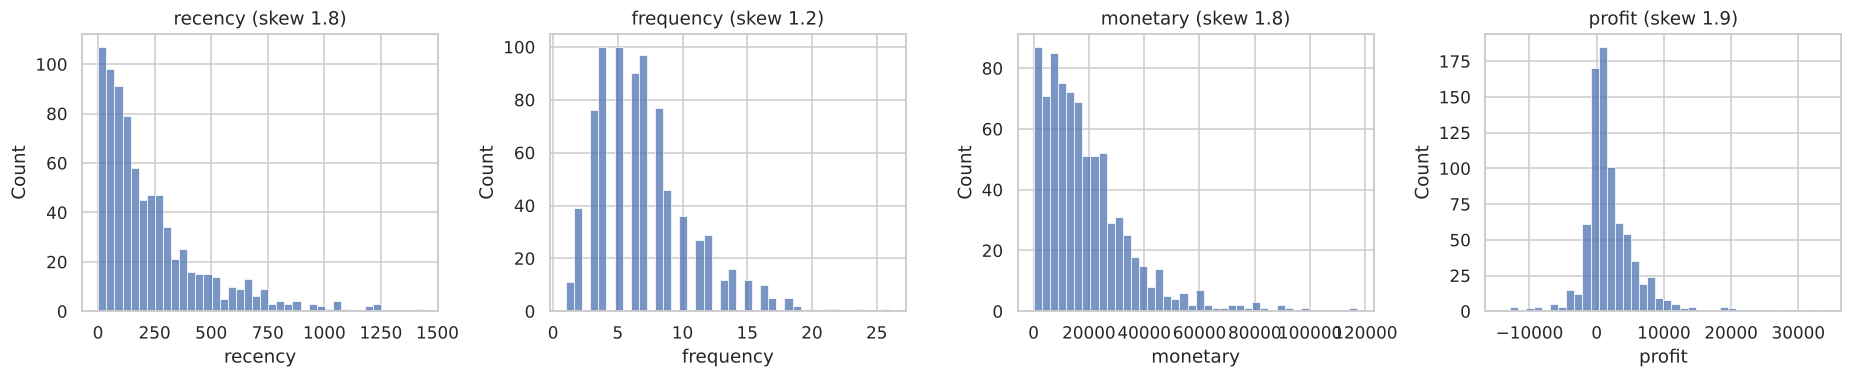

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6))
for ax, col in zip(axes, ["recency", "frequency", "monetary", "profit"]):
    sns.histplot(cust[col], bins=40, ax=ax); ax.set_title(f"{col} (skew {cust[col].skew():.1f})")
plt.tight_layout(); plt.savefig(IMG / "rfm_distributions.png", bbox_inches="tight"); plt.show()

Monetary and frequency are right-skewed, with a few very big spenders. K-Means uses distances, so a handful of
extreme customers would pull whole clusters around. I'll log-transform the skewed features and standardise
everything before clustering. Profit can be negative, so it gets a signed log transform instead.

## 3. Baseline: rule-based RFM scores

The traditional approach: score each customer 1-5 on R, F and M by quintile, then map score combinations to
named segments. It's fast and easy to explain, so it's a useful reference for the clustering.

In [6]:
r = pd.qcut(cust["recency"], 5, labels=[5, 4, 3, 2, 1]).astype(int)          # recent = high score
f = pd.qcut(cust["frequency"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
m = pd.qcut(cust["monetary"], 5, labels=[1, 2, 3, 4, 5]).astype(int)
cust["R"], cust["F"], cust["M"] = r, f, m

def rfm_label(row):
    if row.R >= 4 and row.F >= 4 and row.M >= 4: return "Champions"
    if row.F >= 4 and row.M >= 3: return "Loyal"
    if row.R >= 4 and row.F <= 2: return "New / promising"
    if row.R <= 2 and row.F >= 3: return "At risk"
    if row.R <= 2 and row.F <= 2: return "Lost / hibernating"
    return "Needs attention"

cust["rfm_segment"] = cust.apply(rfm_label, axis=1)
rfm_summary = cust.groupby("rfm_segment").agg(customers=("recency", "size"), recency=("recency", "median"),
                                              orders=("frequency", "median"), spend=("monetary", "median"),
                                              revenue=("monetary", "sum"))
rfm_summary["revenue share"] = rfm_summary["revenue"] / rfm_summary["revenue"].sum()
rfm_summary.sort_values("revenue", ascending=False).style.format({"spend": "${:,.0f}", "revenue": "${:,.0f}", "revenue share": "{:.1%}"})

,customers,recency,orders,spend,revenue,revenue share
rfm_segment,,,,,,
Champions,127,55.000000,11.000000,"$33,725","$4,896,420",32.8%
Loyal,140,199.000000,9.000000,"$21,483","$3,743,008",25.1%
Needs attention,192,125.500000,6.000000,"$10,651","$2,541,972",17.0%
Lost / hibernating,185,448.000000,4.000000,"$7,189","$1,740,799",11.7%
At risk,71,327.000000,6.000000,"$12,532","$1,094,015",7.3%
New / promising,80,64.000000,4.000000,"$8,903","$899,386",6.0%


## 4. K-Means clustering

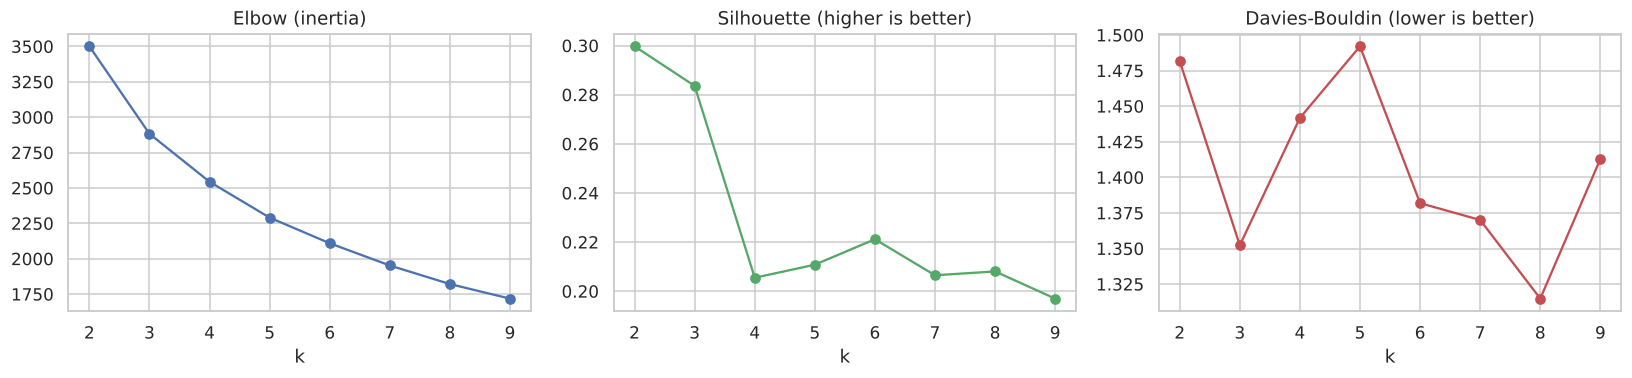

k,2,3,4,5,6,7,8,9
silhouette,0.300,0.284,0.205,0.211,0.221,0.206,0.208,0.197
davies_bouldin,1.482,1.352,1.442,1.492,1.382,1.370,1.315,1.413


In [7]:
features = ["recency", "frequency", "monetary", "profit", "avg_discount", "n_categories"]
Xc = cust[features].copy()
for c in ["frequency", "monetary"]:
    Xc[c] = np.log1p(Xc[c])
Xc["recency"] = np.log1p(Xc["recency"])
Xc["profit"] = np.sign(Xc["profit"]) * np.log1p(np.abs(Xc["profit"]))
X = StandardScaler().fit_transform(Xc)

ks = range(2, 10)
inertia, sil, dbi = [], [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=20, random_state=SEED).fit(X)
    inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_)); dbi.append(davies_bouldin_score(X, km.labels_))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.6))
axes[0].plot(ks, inertia, "o-"); axes[0].set(title="Elbow (inertia)", xlabel="k")
axes[1].plot(ks, sil, "o-", color="#55A868"); axes[1].set(title="Silhouette (higher is better)", xlabel="k")
axes[2].plot(ks, dbi, "o-", color="#C44E52"); axes[2].set(title="Davies-Bouldin (lower is better)", xlabel="k")
plt.tight_layout(); plt.savefig(IMG / "choosing_k.png", bbox_inches="tight"); plt.show()
pd.DataFrame({"k": list(ks), "silhouette": sil, "davies_bouldin": dbi}).round(3).set_index("k").T

Picking k is partly statistics, partly usefulness.

- The elbow plot has no sharp bend, and silhouette scores are modest everywhere (0.20-0.30). That's normal for
  customer data: buying behaviour is a continuum, not neat separate blobs.
- **k = 2 scores best**, but it only splits "big customers" from "small customers", which marketing already
  knows.
- Silhouette drops at k = 4 and then stays flat through k = 8, so going beyond 4 adds complexity without
  cleaner groups.

I go with **k = 4**: it's the smallest number that separates the groups marketing would actually treat
differently (in particular, it isolates the loss-making customers, as shown below).

In [8]:
K = 4
km = KMeans(n_clusters=K, n_init=50, random_state=SEED).fit(X)
cust["cluster"] = km.labels_
print(f"k = {K}: silhouette {silhouette_score(X, km.labels_):.3f}, Davies-Bouldin {davies_bouldin_score(X, km.labels_):.3f}")
print(cust["cluster"].value_counts().sort_index().to_dict())

k = 4: silhouette 0.206, Davies-Bouldin 1.437
{0: 142, 1: 211, 2: 167, 3: 275}


## 5. Profiling the clusters

In [9]:
profile = cust.groupby("cluster").agg(customers=("recency", "size"), recency_days=("recency", "median"),
                                      orders=("frequency", "median"), spend=("monetary", "median"),
                                      profit=("profit", "median"), avg_discount=("avg_discount", "mean"),
                                      categories=("n_categories", "mean"), revenue=("monetary", "sum"),
                                      total_profit=("profit", "sum"))
profile["revenue share"] = profile["revenue"] / profile["revenue"].sum()
profile["profit share"] = profile["total_profit"] / profile["total_profit"].sum()
profile.round(2)

,customers,recency_days,orders,spend,profit,avg_discount,categories,revenue,total_profit,revenue share,profit share
cluster,,,,,,,,,,,
0,142,307.0,3.0,2904.84,100.94,0.05,1.86,575639.62,34068.03,0.04,0.02
1,211,60.0,10.0,27762.45,3926.09,0.05,2.92,6818393.17,1066940.39,0.46,0.70
2,167,127.0,6.0,12532.47,-1102.90,0.05,2.87,2569220.48,-340980.69,0.17,-0.22
3,275,248.0,6.0,16010.50,1890.36,0.05,2.85,4952347.56,761740.25,0.33,0.50


In [10]:
# Name clusters from their profile: rank by spend and recency so the names don't depend on random label order
names = {}
rest = profile.copy()
top = rest["spend"].idxmax(); names[top] = "Champions"; rest = rest.drop(index=top)
loss = rest["profit"].idxmin(); names[loss] = "Loss-making buyers"; rest = rest.drop(index=loss)
lapsed = rest["recency_days"].idxmax(); names[lapsed] = "Lapsed"; rest = rest.drop(index=lapsed)
for c in rest.index: names[c] = "Profitable, cooling off"
cust["segment_name"] = cust["cluster"].map(names)
profile.index = profile.index.map(names)
profile = profile.sort_values("spend", ascending=False)
profile[["customers", "recency_days", "orders", "spend", "profit", "revenue share", "profit share"]].style.format(
    {"spend": "${:,.0f}", "profit": "${:,.0f}", "revenue share": "{:.1%}", "profit share": "{:.1%}", "recency_days": "{:.0f}", "orders": "{:.0f}"})

,customers,recency_days,orders,spend,profit,revenue share,profit share
cluster,,,,,,,
Champions,211,60,10,"$27,762","$3,926",45.7%,70.1%
"Profitable, cooling off",275,248,6,"$16,011","$1,890",33.2%,50.1%
Loss-making buyers,167,127,6,"$12,532","$-1,103",17.2%,-22.4%
Lapsed,142,307,3,"$2,905",$101,3.9%,2.2%


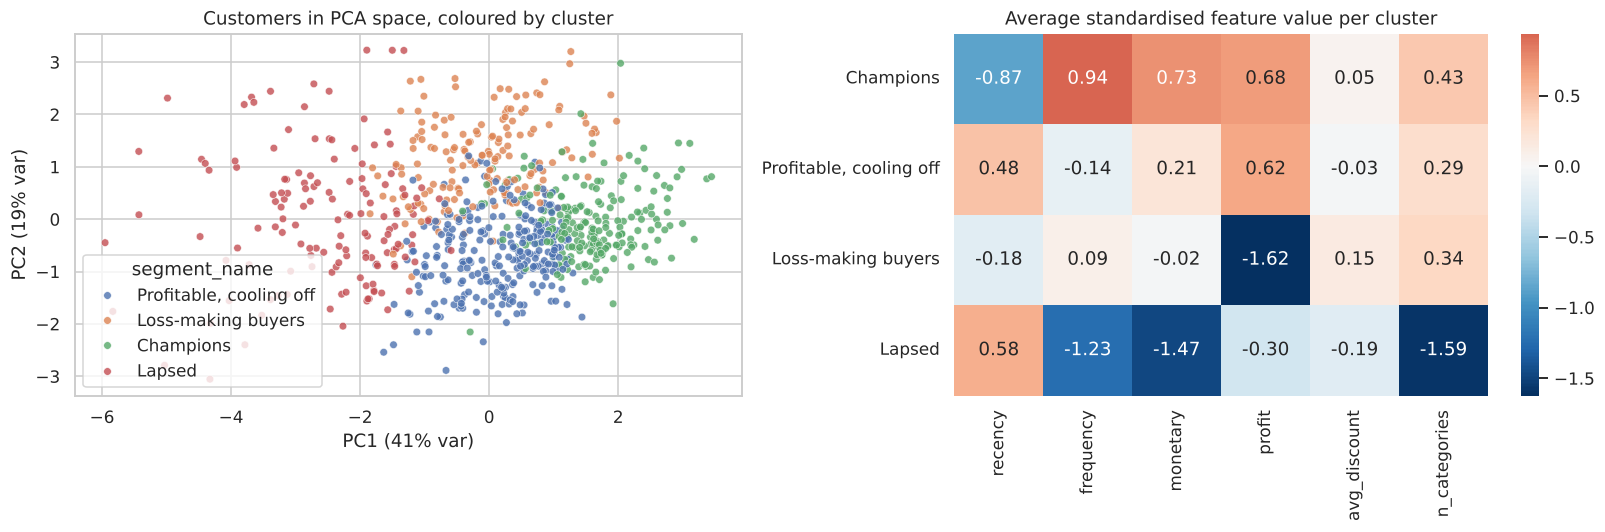

In [11]:
pca = PCA(n_components=2, random_state=SEED).fit(X)
pcs = pca.transform(X)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.scatterplot(x=pcs[:, 0], y=pcs[:, 1], hue=cust["segment_name"], s=25, alpha=0.8, ax=axes[0])
axes[0].set(xlabel=f"PC1 ({pca.explained_variance_ratio_[0]:.0%} var)", ylabel=f"PC2 ({pca.explained_variance_ratio_[1]:.0%} var)",
            title="Customers in PCA space, coloured by cluster")
z = pd.DataFrame(X, columns=features).groupby(cust["segment_name"].values).mean().loc[profile.index]
sns.heatmap(z, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[1])
axes[1].set(title="Average standardised feature value per cluster", ylabel="")
plt.tight_layout(); plt.savefig(IMG / "clusters.png", bbox_inches="tight"); plt.show()

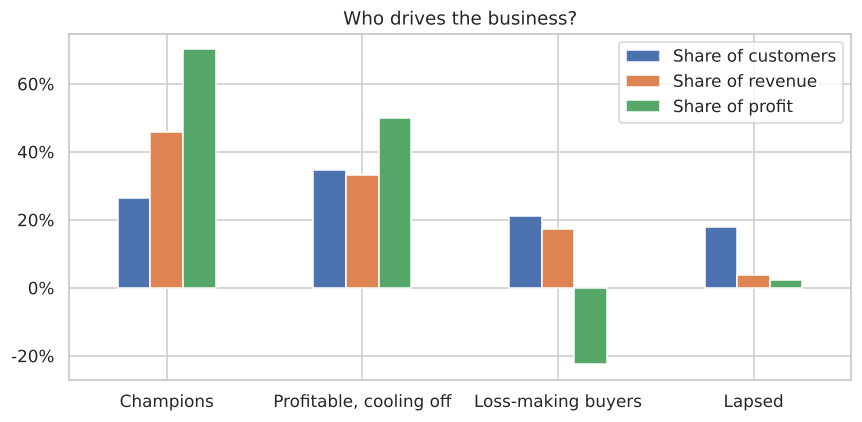

In [12]:
fig, ax = plt.subplots(figsize=(8, 4))
share = profile[["customers", "revenue share", "profit share"]].copy()
share["customers"] = share["customers"] / share["customers"].sum()
share.columns = ["Share of customers", "Share of revenue", "Share of profit"]
share.plot.bar(ax=ax); ax.tick_params(axis="x", rotation=0)
ax.yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set(xlabel="", title="Who drives the business?")
plt.tight_layout(); plt.savefig(IMG / "segment_value.png", bbox_inches="tight"); plt.show()

The four segments:

| Segment | Who they are |
|---|---|
| **Champions** (211, 27% of customers) | Ordered recently (median 60 days ago), about 10 orders, ~$28k spend each. **46% of revenue and 70% of profit.** |
| **Profitable, cooling off** (275, 35%) | Good, profitable customers, but their last order was a median 248 days ago. 33% of revenue, 50% of profit. |
| **Loss-making buyers** (167, 21%) | Spend real money (~$12.5k each) but **lose the company $341k in total**, wiping out about 22% of overall profit. |
| **Lapsed** (142, 18%) | Few orders, small spend, last seen ~10 months ago. 4% of revenue. |

Profit shares add up to more than 100% because the loss-making segment's share is negative.
The most interesting group is the loss-making buyers. They look fine on revenue alone, and the rule-based RFM
scoring scatters them across every one of its segments (even "Champions"). Only by adding profit to the
clustering do they show up as a group.

### Why are the loss-making buyers losing money?

In [13]:
o = orders.merge(cust[["segment_name"]], left_on="Customer Name", right_index=True)
o["loss_line"] = o["Profit"] < 0
why = o.groupby("segment_name").agg(avg_discount=("Discount", "mean"), loss_lines=("loss_line", "mean"),
                                    ship_cost_per_line=("Shipping Cost", "mean"), unit_price=("Unit Price", "mean"),
                                    margin=("Product Base Margin", "mean"))
cat_mix = pd.crosstab(o["segment_name"], o["Product Category"], values=o["Sales"], aggfunc="sum", normalize="index")
loss_by_cat = o.groupby(["segment_name", "Product Category"])["Profit"].sum().unstack()
display(why.loc[profile.index].round(3)); display(cat_mix.loc[profile.index].round(3)); display(loss_by_cat.loc[profile.index].round(0))

,avg_discount,loss_lines,ship_cost_per_line,unit_price,margin
cluster,,,,,
Champions,0.050,0.482,12.708,88.408,0.508
"Profitable, cooling off",0.049,0.462,12.216,82.858,0.512
Loss-making buyers,0.051,0.626,15.478,111.480,0.528
Lapsed,0.047,0.505,8.760,59.428,0.496


Product Category,Furniture,Office Supplies,Technology
cluster,,,
Champions,0.325,0.252,0.422
"Profitable, cooling off",0.341,0.261,0.398
Loss-making buyers,0.458,0.215,0.327
Lapsed,0.172,0.320,0.508


Product Category,Furniture,Office Supplies,Technology
cluster,,,
Champions,135153.0,323155.0,608633.0
"Profitable, cooling off",155077.0,213388.0,393276.0
Loss-making buyers,-171179.0,-27373.0,-142429.0
Lapsed,-1618.0,8852.0,26834.0


Discounts are the same across all segments (~5%), so discounting isn't the problem. What's different about the
loss-making buyers:
- **63% of their order lines lose money**, vs 46-48% for the profitable segments
- **Higher shipping cost per line** ($15.5 vs ~$12.5) and pricier items on average
- **A furniture-heavy mix** (46% of their spend vs ~33%), and they lose money on both furniture and technology

So the problem looks like **bulky, expensive-to-ship orders** where shipping eats the margin, not price-sensitive
customers chasing deals.

### How do the clusters line up with the rule-based RFM segments?

In [14]:
pd.crosstab(cust["segment_name"], cust["rfm_segment"]).loc[profile.index]

rfm_segment,At risk,Champions,Lost / hibernating,Loyal,Needs attention,New / promising
cluster,,,,,,
Champions,0,110,0,54,36,11
"Profitable, cooling off",48,0,74,60,71,22
Loss-making buyers,16,17,26,26,58,24
Lapsed,7,0,85,0,27,23


In [15]:
Path("results").mkdir(exist_ok=True)
cust[["segment_name", "rfm_segment", "recency", "frequency", "monetary", "profit"]].to_csv("results/customer_segments.csv")
results = {
    "k": K, "silhouette": round(float(silhouette_score(X, km.labels_)), 3),
    "silhouette_by_k": dict(zip(map(str, ks), [round(float(s), 3) for s in sil])),
    "profile": profile[["customers", "recency_days", "orders", "spend", "profit", "revenue share", "profit share"]].round(3).reset_index().rename(columns={"cluster": "segment"}).to_dict(orient="records"),
    "n_customers": int(len(cust)), "n_orders": int(orders["Order ID"].nunique()),
}
json.dump(results, open("results/metrics.json", "w"), indent=2, default=str)
results

{'k': 4,
 'silhouette': 0.206,
 'silhouette_by_k': {'2': 0.3,
  '3': 0.284,
  '4': 0.205,
  '5': 0.211,
  '6': 0.221,
  '7': 0.206,
  '8': 0.208,
  '9': 0.197},
 'profile': [{'segment': 'Champions',
   'customers': 211,
   'recency_days': 60.0,
   'orders': 10.0,
   'spend': 27762.452,
   'profit': 3926.09,
   'revenue share': 0.457,
   'profit share': 0.701},
  {'segment': 'Profitable, cooling off',
   'customers': 275,
   'recency_days': 248.0,
   'orders': 6.0,
   'spend': 16010.503,
   'profit': 1890.36,
   'revenue share': 0.332,
   'profit share': 0.501},
  {'segment': 'Loss-making buyers',
   'customers': 167,
   'recency_days': 127.0,
   'orders': 6.0,
   'spend': 12532.471,
   'profit': -1102.9,
   'revenue share': 0.172,
   'profit share': -0.224},
  {'segment': 'Lapsed',
   'customers': 142,
   'recency_days': 307.0,
   'orders': 3.0,
   'spend': 2904.835,
   'profit': 100.94,
   'revenue share': 0.039,
   'profit share': 0.022}],
 'n_customers': 795,
 'n_orders': 5496}

## Takeaways and recommended actions

| Segment | Action |
|---|---|
| **Champions** | Protect them: account manager, early access, volume pricing. Losing a few of these hurts more than anything else. |
| **Profitable, cooling off** | The biggest opportunity. They're profitable but drifting away, so a win-back campaign here has the best expected return. |
| **Loss-making buyers** | Don't chase more of their volume. Review shipping charges and minimum order values on bulky furniture/tech orders before spending marketing money on them. |
| **Lapsed** | Low-cost automated re-engagement only. |

**Method notes:** silhouette scores are modest (~0.2), so these are useful groupings of a continuum, not sharply
separated types of customer. The main thing clustering added over rule-based RFM was the profit dimension, which
exposed a segment that RFM alone would have treated as good customers.